In [18]:
import pandas as pd
import sys
import matplotlib.pyplot as plt
sys.path.append("..")
from src.fixed_data import fix_data
df = pd.read_csv("../data/processed/alzheimer.csv")
df = fix_data(df)

In [19]:
status_counts =df["status"].value_counts()

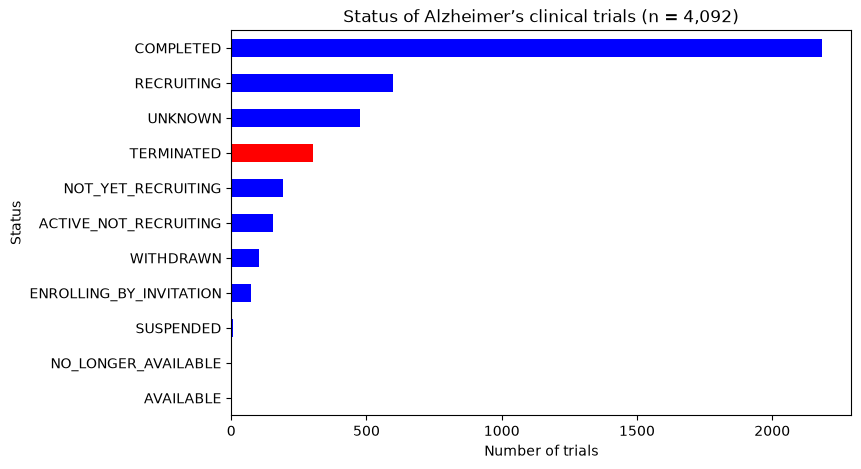

In [29]:
fig, ax = plt.subplots(figsize=(8, 5))
colors =[]
for name in status_counts.index:
    if name =="TERMINATED":
        colors.append("red")
    else:
        colors.append("blue")
status_counts.plot(kind ="barh",ax=ax,color =colors)
ax.set_title("Status of Alzheimer’s clinical trials (n = 4,092)")
ax.set_xlabel("Number of trials")
ax.set_ylabel("Status")
ax.invert_yaxis()


In [31]:
plt.tight_layout()
fig.savefig("../figures/01_status.png", dpi=150, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [34]:
phase_counts = df["phases"].fillna("No phase (observational)").value_counts(dropna=False)

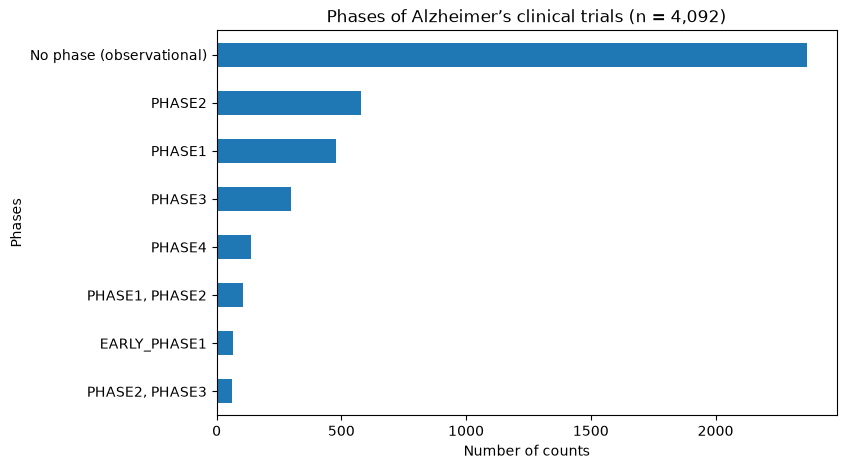

In [38]:
fig, ax = plt.subplots(figsize=(8, 5))
phase_counts.plot(kind ="barh",ax=ax)
ax.set_title("Phases of Alzheimer’s clinical trials (n = 4,092)")
ax.set_xlabel("Number of trials")
ax.set_ylabel("Phases")
ax.invert_yaxis()

In [39]:
plt.tight_layout()
fig.savefig("../figures/02_phases.png", dpi=150, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [40]:
from src.analysis import termination_by_phase
 

In [41]:
rates = termination_by_phase(df)

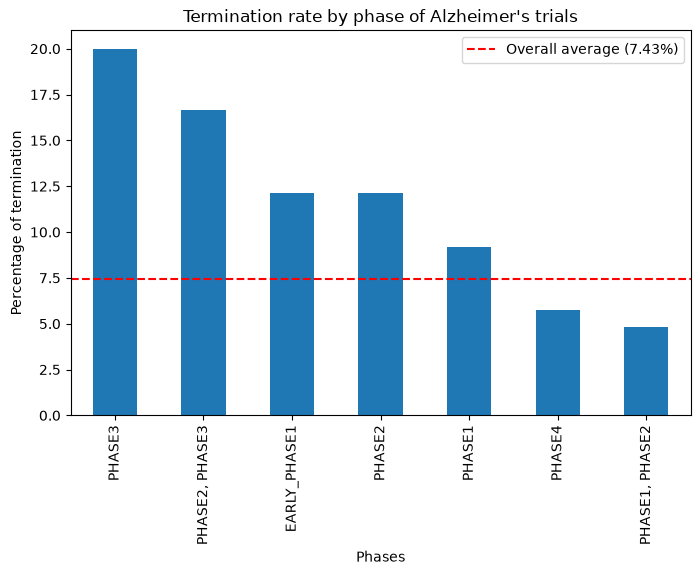

In [49]:
fig, ax = plt.subplots(figsize=(8, 5))
rates.plot(kind = "bar",ax= ax)
ax.set_title("Termination rate by phase of Alzheimer's trials")
ax.set_xlabel("Phases")
ax.set_ylabel("Percentage of termination")
ax.axhline(7.43, color = "red",linestyle="--", label="Overall average (7.43%)")
ax.legend()

In [50]:
plt.tight_layout()
fig.savefig("../figures/03_termination_by_phase.png", dpi=150, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [52]:
from src.analysis import categorize_text
mask = df["status"].isin(["TERMINATED","SUSPENDED","WITHDRAWN"])
stopped = df[mask].copy()
stopped["cleaned_data"] = stopped["why_stopped"].str.lower().str.strip()
stopped["reason_category"] = stopped["cleaned_data"].apply(categorize_text)
reason_pct = (stopped["reason_category"].value_counts(normalize=True)*100).round(2)


reason_category
other              28.57
recruitment        19.13
missing            14.04
funding            11.38
efficacy            9.44
covid               6.30
investigator        5.08
safety              2.66
administrative      1.94
see description     1.45
Name: proportion, dtype: float64

Text(0, 0.5, 'Reason')

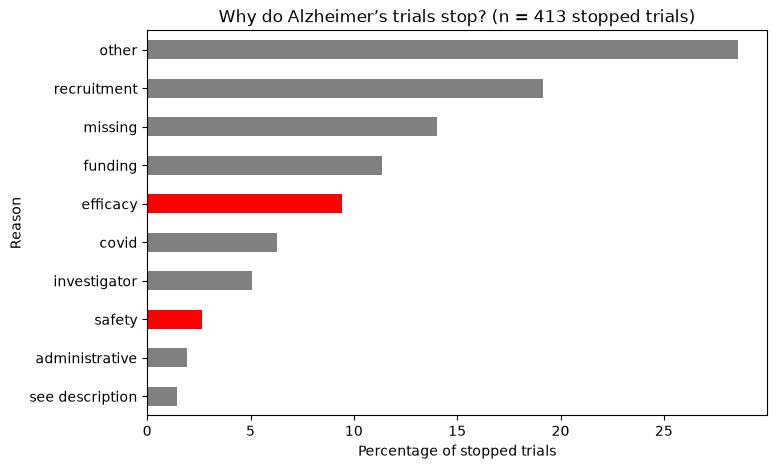

In [65]:
fig, ax = plt.subplots(figsize=(8, 5))
colors = []
for name in reason_pct.index:
    if name == "efficacy":
        colors.append("red")
    elif name == "safety":
        colors.append("red")
    else:
        colors.append("grey")
reason_pct.plot(kind = "barh",ax=ax,color =colors)
ax.invert_yaxis()
ax.set_xlabel("Percentage of stopped trials")
ax.set_title("Why do Alzheimer’s trials stop? (n = 413 stopped trials)")
ax.set_ylabel("Reason")

In [66]:
plt.tight_layout()
fig.savefig("../figures/04_why_trials_stop.png", dpi=150, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [67]:
reasons_by_phase = (pd.crosstab(stopped["phases"],stopped["reason_category"],normalize ="index" )*100).round(2)
reasons_by_phase = reasons_by_phase.loc[["PHASE1","PHASE2","PHASE3"]]

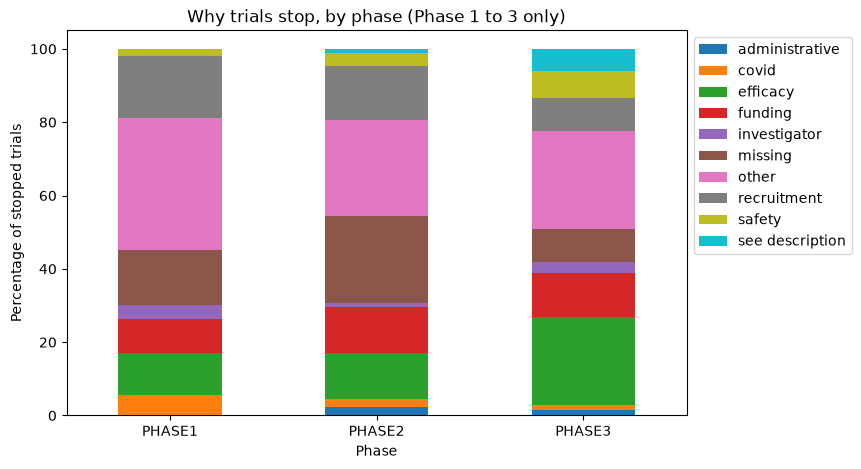

In [71]:
fig, ax = plt.subplots(figsize=(8, 5))
reasons_by_phase.plot(kind = "bar",stacked= True,ax= ax)
ax.legend(bbox_to_anchor=(1,1))
ax.set_title("Why trials stop, by phase (Phase 1 to 3 only)")
ax.set_xlabel("Phase")
ax.set_ylabel("Percentage of stopped trials")
ax.tick_params(axis = "x",rotation = 0)

In [72]:
plt.tight_layout()
fig.savefig("../figures/05_reasons_by_phase.png", dpi=150, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>